# Heart Failure Survival Prediction: A Fair Benchmark against Chicco & Jurman (2020)

Predicting death of heart failure patients from routine clinical records with **Random Forest** and **Gradient Boosting**, benchmarked against **Chicco & Jurman (2020)**, *BMC Medical Informatics and Decision Making* ([DOI: 10.1186/s12911-020-1023-5](https://doi.org/10.1186/s12911-020-1023-5)).

> **About this version.** This project started as a Data Analytics group assignment at Universiti Malaya. The original version compared a single train/test split that included the `time` (follow-up period) feature against the paper's average over 100 runs without it. That comparison was not like-for-like. This version repeats the benchmark under the paper's conditions, so that every improvement reported here is a fair one.

## 1. Executive Summary

### Problem
Heart failure is a major cause of cardiovascular death. If mortality risk can be predicted from data that hospitals already collect, clinicians can prioritise follow-up for high-risk patients. The task is binary classification: `DEATH_EVENT = 1` if the patient died during the follow-up period, `0` otherwise.

### Research baseline
Chicco & Jurman (2020), Table 4: survival prediction using all clinical features, **mean of 100 executions**.

| Model | MCC | F1-Score | Accuracy | TP rate (recall) | ROC AUC |
|---|---|---|---|---|---|
| Random Forest | +0.384 | 0.547 | 0.740 | 0.491 | 0.800 |
| Gradient Boosting | +0.367 | 0.527 | 0.738 | 0.477 | 0.754 |

### Evaluation protocol (same conditions as the paper)
1. **`time` is excluded.** It is the follow-up period, not a clinical measurement, and the paper analyses it separately (see Section 9).
2. **100 random 80/20 train/test splits**, with results reported as mean ± standard deviation, not a single lucky or unlucky split.
3. **Every model is evaluated on the same 100 splits**, so the differences between models are paired and directly comparable.

### Pipeline
| Stage | Change | Question |
|---|---|---|
| 1 | Default RF and GB | Can we reproduce the paper? |
| 2 | + SMOTE (training data only) | Does handling class imbalance help? |
| 3 | + Hyperparameter tuning (nested, scored on MCC) | Does tuning help on 299 patients? |

## 2. Setup

In [2]:
from pathlib import Path
import time as timer

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             matthews_corrcoef, recall_score)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

# config
DATA_PATH    = Path('../data/heart_failure_clinical_records_dataset.csv')
IMG_DIR      = Path('../images')
RESULTS_DIR  = Path('../results')
RANDOM_STATE = 42
N_SPLITS     = 100   # same number of executions as the paper
TEST_SIZE    = 0.20  # 80/20 split
TARGET       = 'DEATH_EVENT'

IMG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
SURVIVED_COLOR, DIED_COLOR = '#2ecc71', '#e74c3c'

In [3]:
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]} patients, {df.shape[1]} columns")
df.head()

Shape: 299 patients, 13 columns


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


## 3. Data Overview
The dataset contains 299 patients from the Faisalabad Institute of Cardiology, Pakistan (April to December 2015), with 11 clinical features, the follow-up period (`time`) and the target (`DEATH_EVENT`).

In [4]:
overview = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isnull().sum(),
    'unique values': df.nunique(),
})
overview

,dtype,missing,unique values
age,float64,0,47
anaemia,int64,0,2
creatinine_phosphokinase,int64,0,208
diabetes,int64,0,2
ejection_fraction,int64,0,17
high_blood_pressure,int64,0,2
platelets,float64,0,176
serum_creatinine,float64,0,40
serum_sodium,int64,0,27
sex,int64,0,2


In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,299.0,60.83,11.89,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.43,0.50,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.84,970.29,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.08,11.83,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.35,0.48,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.03,97804.24,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.39,1.03,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.63,4.41,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.65,0.48,0.0,0.0,1.0,1.0,1.0


In [6]:
counts = df[TARGET].value_counts().sort_index()
print(f"Survived (0): {counts[0]} ({counts[0]/len(df):.1%})")
print(f"Died     (1): {counts[1]} ({counts[1]/len(df):.1%})")

Survived (0): 203 (67.9%)
Died     (1): 96 (32.1%)


No values are missing and every column is numeric, so no cleaning or encoding is needed. The classes are **imbalanced (about 68/32)**: a model that always predicts "survived" would already score 67.9% accuracy. For this reason MCC is the main metric, as it is in the paper, with F1-Score and recall reported alongside accuracy.

## 4. Exploratory Data Analysis

### 4.1 Class distribution

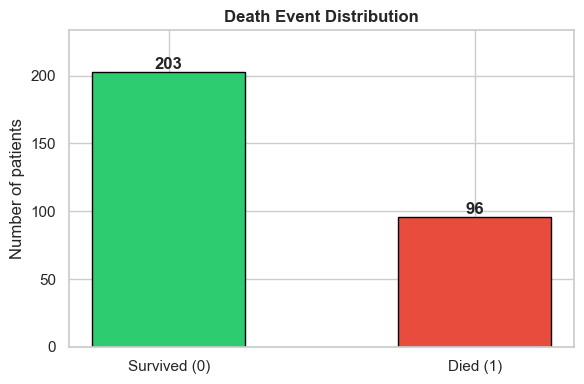

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Survived (0)', 'Died (1)'], counts, color=[SURVIVED_COLOR, DIED_COLOR],
              edgecolor='black', width=0.5)
ax.bar_label(bars, fontweight='bold')
ax.set_title('Death Event Distribution', fontweight='bold')
ax.set_ylabel('Number of patients')
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.savefig(IMG_DIR / 'class_distribution.png', dpi=150)
plt.show()

### 4.2 Correlation with the target

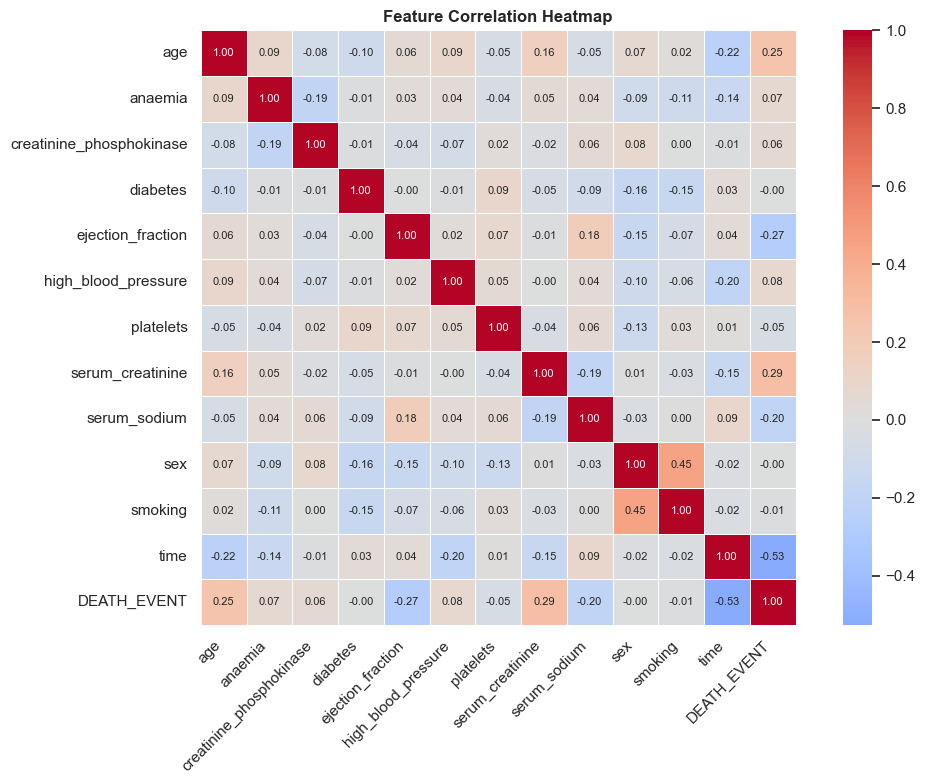

,correlation with DEATH_EVENT
time,-0.527
serum_creatinine,0.294
ejection_fraction,-0.269
age,0.254
serum_sodium,-0.195
high_blood_pressure,0.079
anaemia,0.066
creatinine_phosphokinase,0.063
platelets,-0.049
smoking,-0.013


In [8]:
corr = df.corr()

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True,
            linewidths=0.5, annot_kws={'size': 8}, ax=ax)
ax.set_title('Feature Correlation Heatmap', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(IMG_DIR / 'correlation_heatmap.png', dpi=150)
plt.show()

corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame('correlation with DEATH_EVENT')

- **`time` has the strongest correlation (-0.53)**, but it is the follow-up period, not a clinical measurement. Section 4.4 explains why it cannot be used as a predictor.
- Among the clinical features, **serum creatinine (+0.29)**, **ejection fraction (-0.27)**, **age (+0.25)** and **serum sodium (-0.20)** are most associated with death. This matches the paper's main finding.
- The binary features (anaemia, diabetes, high blood pressure, sex, smoking) are only weakly correlated with the outcome.

### 4.3 Key clinical features by outcome

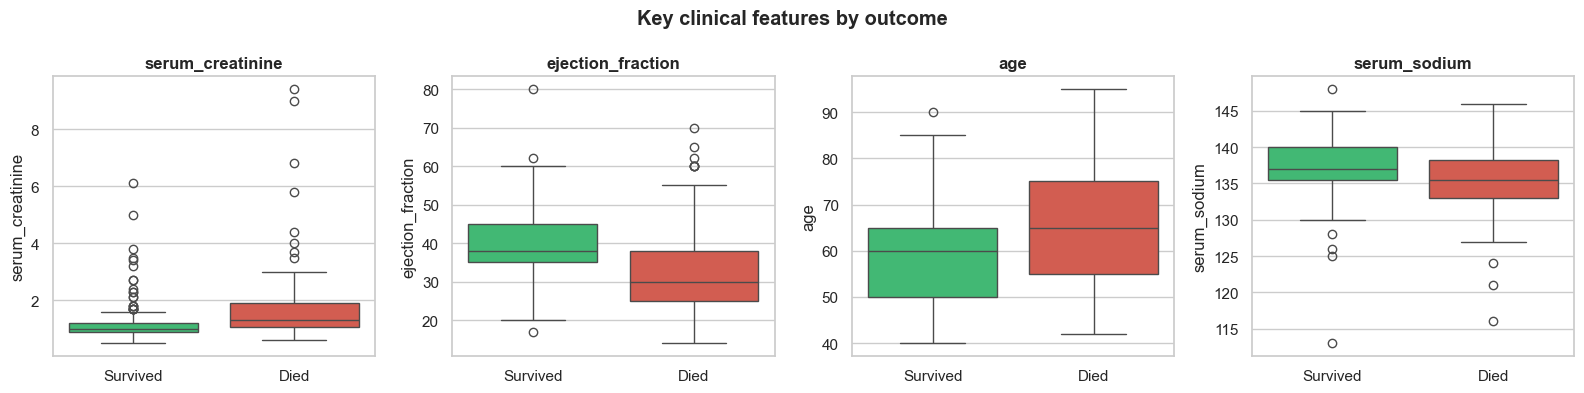

,serum_creatinine,ejection_fraction,age,serum_sodium
DEATH_EVENT,,,,
Survived (median),1.0,38.0,60.0,137.0
Died (median),1.3,30.0,65.0,135.5


In [9]:
key_features = ['serum_creatinine', 'ejection_fraction', 'age', 'serum_sodium']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, feature in zip(axes, key_features):
    sns.boxplot(data=df, x=TARGET, y=feature, hue=TARGET, ax=ax, legend=False,
                palette=[SURVIVED_COLOR, DIED_COLOR])
    ax.set_xticks([0, 1], ['Survived', 'Died'])
    ax.set_xlabel('')
    ax.set_title(feature, fontweight='bold')
plt.suptitle('Key clinical features by outcome', fontweight='bold')
plt.tight_layout()
plt.savefig(IMG_DIR / 'key_features_by_outcome.png', dpi=150)
plt.show()

df.groupby(TARGET)[key_features].median().rename(index={0: 'Survived (median)', 1: 'Died (median)'}).round(2)

Patients who died had **higher serum creatinine** (a sign of poorer kidney function), **lower ejection fraction** (the heart pumps less blood with each beat), were **older**, and had **lower serum sodium**. The serum creatinine distribution is strongly right-skewed with clear outliers. Tree-based models are not affected by skew, so no transformation or scaling is applied.

### 4.4 Why `time` is excluded

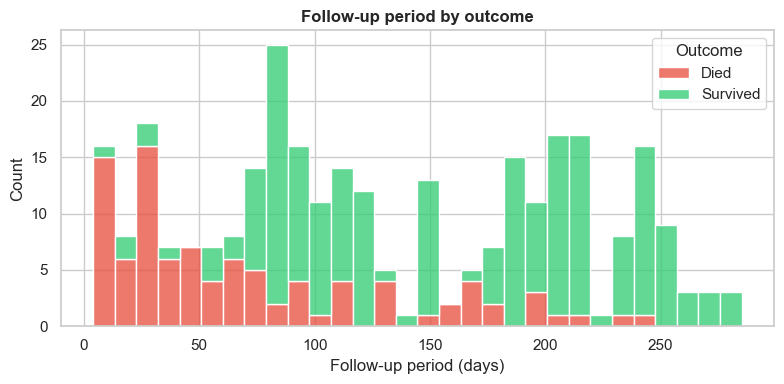

DEATH_EVENT
Survived    172.0
Died         44.5


In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x='time', hue=TARGET, bins=30, multiple='stack',
             palette=[SURVIVED_COLOR, DIED_COLOR], ax=ax)
ax.legend(['Died', 'Survived'], title='Outcome')
ax.set_title('Follow-up period by outcome', fontweight='bold')
ax.set_xlabel('Follow-up period (days)')
plt.tight_layout()
plt.show()

print(df.groupby(TARGET)['time'].median().rename({0: 'Survived', 1: 'Died'}).to_string())

Most deaths happen in patients with a short follow-up, because **follow-up ends when the patient dies**. The value of `time` therefore partly depends on the outcome, and it is not known when a prediction would be made. Using it as a feature is a form of **target leakage**: it makes the model look more accurate than it would be in practice. The paper treats follow-up time in a separate analysis, so it is excluded from the benchmark here. Section 9 measures how much it inflates the results.

## 5. Evaluation Protocol
- **Features:** the 11 clinical features (`time` excluded).
- **Splits:** 100 stratified 80/20 train/test splits (seeds 0 to 99). Each split has about 239 training and 60 test patients with the same 68/32 class ratio.
- **Paired comparison:** every model sees exactly the same 100 splits.
- **SMOTE inside the pipeline:** oversampling is fitted on the training data of each split (and of each cross-validation fold during tuning), so no synthetic data leaks into evaluation.
- **Metrics:** MCC (main metric), F1-Score, accuracy, recall (the paper's TP rate) and ROC AUC.

In [11]:
CLINICAL_FEATURES = [c for c in df.columns if c not in (TARGET, 'time')]
X = df[CLINICAL_FEATURES]
y = df[TARGET]

SPLITS = [
    train_test_split(np.arange(len(df)), test_size=TEST_SIZE, stratify=y, random_state=seed)
    for seed in range(N_SPLITS)
]
print(f"Features ({len(CLINICAL_FEATURES)}): {CLINICAL_FEATURES}")
print(f"{N_SPLITS} splits | train size: {len(SPLITS[0][0])} | test size: {len(SPLITS[0][1])}")

Features (11): ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking']
100 splits | train size: 239 | test size: 60


In [12]:
METRICS = ['MCC', 'F1', 'Accuracy', 'Recall', 'ROC AUC']

def evaluate(model, X, y, name, splits=SPLITS):
    # Fit a fresh copy of `model` on each split and return the per-split test metrics.
    rows, best_params = [], []
    start = timer.time()
    for i, (train_idx, test_idx) in enumerate(splits):
        m = clone(model).fit(X.iloc[train_idx], y.iloc[train_idx])
        y_test = y.iloc[test_idx]
        pred = m.predict(X.iloc[test_idx])
        prob = m.predict_proba(X.iloc[test_idx])[:, 1]
        rows.append({
            'Model': name, 'split': i,
            'MCC': matthews_corrcoef(y_test, pred),
            'F1': f1_score(y_test, pred),
            'Accuracy': accuracy_score(y_test, pred),
            'Recall': recall_score(y_test, pred),
            'ROC AUC': roc_auc_score(y_test, prob),
        })
        if hasattr(m, 'best_params_'):
            best_params.append(m.best_params_)
    print(f"{name}: done in {timer.time() - start:.0f}s")
    result = pd.DataFrame(rows)
    result.attrs['best_params'] = best_params
    return result

def summarise(results):
    # Mean ± standard deviation of each metric, one row per model.
    grouped = results.groupby('Model', sort=False)[METRICS]
    mean, std = grouped.mean(), grouped.std()
    return mean.round(3).astype(str) + ' ± ' + std.round(3).astype(str)

PAPER = pd.DataFrame({
    'MCC': [0.384, 0.367], 'F1': [0.547, 0.527], 'Accuracy': [0.740, 0.738],
    'Recall': [0.491, 0.477], 'ROC AUC': [0.800, 0.754],
}, index=['Paper: Random Forest', 'Paper: Gradient Boosting'])

## 6. Stage 1: Baseline (Replicating the Paper)
Default hyperparameters and no resampling, the same setup as the paper.

In [13]:
rf_base = evaluate(RandomForestClassifier(random_state=RANDOM_STATE), X, y, 'RF: baseline')
gb_base = evaluate(GradientBoostingClassifier(random_state=RANDOM_STATE), X, y, 'GB: baseline')

stage1 = pd.concat([rf_base, gb_base])
pd.concat([PAPER.astype(str), summarise(stage1)])

RF: baseline: done in 13s
GB: baseline: done in 10s


,MCC,F1,Accuracy,Recall,ROC AUC
Paper: Random Forest,0.384,0.547,0.74,0.491,0.8
Paper: Gradient Boosting,0.367,0.527,0.738,0.477,0.754
RF: baseline,0.361 ± 0.123,0.525 ± 0.098,0.737 ± 0.049,0.467 ± 0.114,0.783 ± 0.055
GB: baseline,0.348 ± 0.11,0.528 ± 0.089,0.728 ± 0.043,0.489 ± 0.117,0.742 ± 0.061


**The paper is reproduced.** Under the same conditions, both baselines land within one standard deviation of the paper's results on every metric (for example, Random Forest accuracy of about 74% against the paper's 74.0%). The small remaining gap is expected from using Python's scikit-learn instead of the paper's R implementation, and different random splits.

The standard deviations matter as much as the means. With only 60 test patients, Random Forest's MCC moves by more than ±0.1 from split to split, so a single split can make a model look much better or much worse than it really is.

## 7. Stage 2: SMOTE
SMOTE (Synthetic Minority Oversampling Technique) creates synthetic "died" patients in the **training data only**, so the model sees a balanced 50/50 training set. The test set keeps the real 68/32 ratio.

In [14]:
def with_smote(model):
    return Pipeline([('smote', SMOTE(random_state=RANDOM_STATE)), ('model', model)])

rf_smote = evaluate(with_smote(RandomForestClassifier(random_state=RANDOM_STATE)), X, y, 'RF: SMOTE')
gb_smote = evaluate(with_smote(GradientBoostingClassifier(random_state=RANDOM_STATE)), X, y, 'GB: SMOTE')

summarise(pd.concat([rf_base, rf_smote, gb_base, gb_smote]))

RF: SMOTE: done in 14s
GB: SMOTE: done in 11s


,MCC,F1,Accuracy,Recall,ROC AUC
Model,,,,,
RF: baseline,0.361 ± 0.123,0.525 ± 0.098,0.737 ± 0.049,0.467 ± 0.114,0.783 ± 0.055
RF: SMOTE,0.379 ± 0.11,0.571 ± 0.08,0.73 ± 0.048,0.573 ± 0.107,0.768 ± 0.058
GB: baseline,0.348 ± 0.11,0.528 ± 0.089,0.728 ± 0.043,0.489 ± 0.117,0.742 ± 0.061
GB: SMOTE,0.37 ± 0.115,0.57 ± 0.082,0.723 ± 0.051,0.584 ± 0.109,0.746 ± 0.058


**SMOTE changes the type of errors, not the overall quality.**
- **Recall rises** for both models: more patients who died are correctly flagged.
- **Accuracy and MCC fall slightly**, because the models now also flag more survivors as high-risk (more false positives).

In a clinical setting this trade-off can be worth it, since missing a patient who is at risk of dying is usually the more costly error. But SMOTE alone does not make the models better overall.

## 8. Stage 3: Hyperparameter Tuning (Nested)
Tuning is done **inside each training set** with 3-fold stratified cross-validation (nested cross-validation), so the test set is never used to choose hyperparameters. The search optimises **MCC**, not accuracy, because accuracy rewards predicting the majority class. SMOTE stays inside the pipeline, so it is refitted on every fold.

In [15]:
cv_inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rf_grid = {
    'model__max_depth': [None, 5],
    'model__min_samples_leaf': [1, 5],
}
gb_grid = {
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [2, 3],
}

rf_tuned_model = GridSearchCV(with_smote(RandomForestClassifier(random_state=RANDOM_STATE)),
                              rf_grid, scoring='matthews_corrcoef', cv=cv_inner, n_jobs=-1)
gb_tuned_model = GridSearchCV(with_smote(GradientBoostingClassifier(random_state=RANDOM_STATE)),
                              gb_grid, scoring='matthews_corrcoef', cv=cv_inner, n_jobs=-1)

rf_tuned = evaluate(rf_tuned_model, X, y, 'RF: SMOTE + tuned')
gb_tuned = evaluate(gb_tuned_model, X, y, 'GB: SMOTE + tuned')

summarise(pd.concat([rf_smote, rf_tuned, gb_smote, gb_tuned]))

RF: SMOTE + tuned: done in 51s
GB: SMOTE + tuned: done in 36s


,MCC,F1,Accuracy,Recall,ROC AUC
Model,,,,,
RF: SMOTE,0.379 ± 0.11,0.571 ± 0.08,0.73 ± 0.048,0.573 ± 0.107,0.768 ± 0.058
RF: SMOTE + tuned,0.388 ± 0.115,0.585 ± 0.079,0.728 ± 0.053,0.608 ± 0.102,0.769 ± 0.059
GB: SMOTE,0.37 ± 0.115,0.57 ± 0.082,0.723 ± 0.051,0.584 ± 0.109,0.746 ± 0.058
GB: SMOTE + tuned,0.397 ± 0.108,0.593 ± 0.074,0.73 ± 0.049,0.627 ± 0.106,0.758 ± 0.058


In [16]:
for name, res in [('Random Forest', rf_tuned), ('Gradient Boosting', gb_tuned)]:
    chosen = pd.Series([str(p) for p in res.attrs['best_params']]).value_counts()
    print(f"{name}: most often selected hyperparameters (out of {N_SPLITS} splits)")
    print(chosen.head(3).to_string(), '\n')

Random Forest: most often selected hyperparameters (out of 100 splits)
{'model__max_depth': 5, 'model__min_samples_leaf': 5}       31
{'model__max_depth': 5, 'model__min_samples_leaf': 1}       28
{'model__max_depth': None, 'model__min_samples_leaf': 5}    21 

Gradient Boosting: most often selected hyperparameters (out of 100 splits)
{'model__learning_rate': 0.05, 'model__max_depth': 2}    52
{'model__learning_rate': 0.05, 'model__max_depth': 3}    25
{'model__learning_rate': 0.1, 'model__max_depth': 2}     12 



**Tuning gives a small gain.** With SMOTE and tuning combined, both models reach **the highest recall and F1** of all the configurations, and MCC recovers to about the baseline level. The search mostly picked **shallower trees** (Random Forest `max_depth=5`, Gradient Boosting `max_depth=2`) and a lower learning rate. That is consistent with a small dataset, where simpler models overfit less. Section 9.2 checks whether these gains are statistically meaningful.

## 9. Results

### 9.1 Final comparison with the paper

In [17]:
all_results = pd.concat([rf_base, gb_base, rf_smote, gb_smote, rf_tuned, gb_tuned])
final_table = pd.concat([PAPER.astype(str), summarise(all_results)])
final_table

,MCC,F1,Accuracy,Recall,ROC AUC
Paper: Random Forest,0.384,0.547,0.74,0.491,0.8
Paper: Gradient Boosting,0.367,0.527,0.738,0.477,0.754
RF: baseline,0.361 ± 0.123,0.525 ± 0.098,0.737 ± 0.049,0.467 ± 0.114,0.783 ± 0.055
GB: baseline,0.348 ± 0.11,0.528 ± 0.089,0.728 ± 0.043,0.489 ± 0.117,0.742 ± 0.061
RF: SMOTE,0.379 ± 0.11,0.571 ± 0.08,0.73 ± 0.048,0.573 ± 0.107,0.768 ± 0.058
GB: SMOTE,0.37 ± 0.115,0.57 ± 0.082,0.723 ± 0.051,0.584 ± 0.109,0.746 ± 0.058
RF: SMOTE + tuned,0.388 ± 0.115,0.585 ± 0.079,0.728 ± 0.053,0.608 ± 0.102,0.769 ± 0.059
GB: SMOTE + tuned,0.397 ± 0.108,0.593 ± 0.074,0.73 ± 0.049,0.627 ± 0.106,0.758 ± 0.058


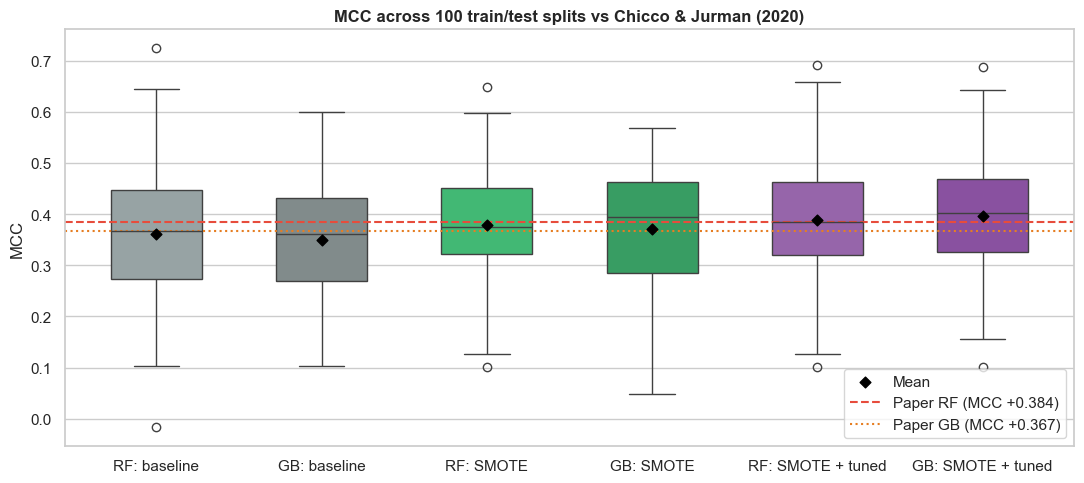

In [19]:
mean_mcc = all_results.groupby('Model', sort=False)['MCC'].mean()
order = mean_mcc.index.tolist()

fig, ax = plt.subplots(figsize=(11, 5))
palette = ['#95a5a6', '#7f8c8d', '#2ecc71', '#27ae60', '#9b59b6', '#8e44ad']
sns.boxplot(data=all_results, x='Model', y='MCC', order=order, hue='Model',
            palette=palette, legend=False, ax=ax, width=0.55)
ax.scatter(range(len(order)), mean_mcc.values, color='black', marker='D', s=30, zorder=3, label='Mean')
ax.axhline(PAPER.loc['Paper: Random Forest', 'MCC'], color='#e74c3c', ls='--',
           label='Paper RF (MCC +0.384)')
ax.axhline(PAPER.loc['Paper: Gradient Boosting', 'MCC'], color='#e67e22', ls=':',
           label='Paper GB (MCC +0.367)')
ax.set_title(f'MCC across {N_SPLITS} train/test splits vs Chicco & Jurman (2020)', fontweight='bold')
ax.set_xlabel('')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(IMG_DIR / 'mcc_comparison.png', dpi=150)
plt.show()

### 9.2 Are the differences real?
Each model is compared with its own baseline on the same 100 splits. The table shows the mean change in MCC and recall, how often the model beat its baseline on MCC, and Wilcoxon signed-rank tests (p < 0.05 means the difference is unlikely to be due to chance).

In [20]:
def fmt_p(p):
    return '< 0.001' if p < 0.001 else f'{p:.3f}'

comparisons = [
    ('RF: SMOTE',         rf_smote, rf_base),
    ('RF: SMOTE + tuned', rf_tuned, rf_base),
    ('GB: SMOTE',         gb_smote, gb_base),
    ('GB: SMOTE + tuned', gb_tuned, gb_base),
]
rows = []
for name, new, base in comparisons:
    diff = new['MCC'].values - base['MCC'].values
    rows.append({
        'Model vs its baseline': name,
        'Mean ΔMCC': round(diff.mean(), 3),
        'Mean ΔRecall': round((new['Recall'].values - base['Recall'].values).mean(), 3),
        'Splits better / worse': f"{(diff > 0).sum()} / {(diff < 0).sum()}",
        'p-value (MCC)': fmt_p(wilcoxon(new['MCC'], base['MCC']).pvalue),
        'p-value (Recall)': fmt_p(wilcoxon(new['Recall'], base['Recall']).pvalue),
    })
significance = pd.DataFrame(rows).set_index('Model vs its baseline')
significance

,Mean ΔMCC,Mean ΔRecall,Splits better / worse,p-value (MCC),p-value (Recall)
Model vs its baseline,,,,,
RF: SMOTE,0.018,0.106,57 / 41,0.058,< 0.001
RF: SMOTE + tuned,0.027,0.141,57 / 42,0.013,< 0.001
GB: SMOTE,0.022,0.095,59 / 40,0.035,< 0.001
GB: SMOTE + tuned,0.049,0.138,66 / 33,< 0.001,< 0.001


- **Recall gains are real.** Every SMOTE configuration catches more of the patients who died, and the recall improvements are consistent across splits.
- **MCC gains are not.** No configuration improves MCC by more than about 0.02, and the p-values show these differences could easily be due to chance. Each model beats its baseline on MCC in only about 40 to 55 of the 100 splits.

**Conclusion:** On this dataset, SMOTE and tuning are a way to choose the **balance between missed deaths and false alarms**, not a way to get a better model overall. With only 299 patients, the information in the 11 clinical features, not the choice of algorithm, limits performance.

### 9.3 Feature importance

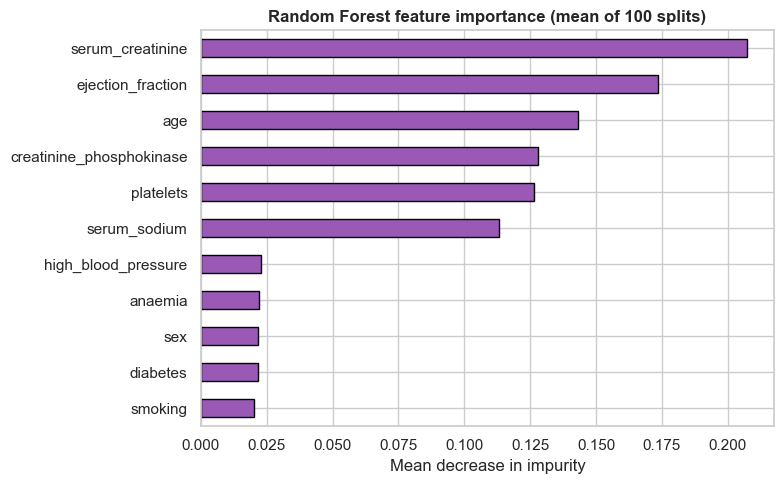

,importance
serum_creatinine,0.207
ejection_fraction,0.174
age,0.143
creatinine_phosphokinase,0.128
platelets,0.127
serum_sodium,0.113
high_blood_pressure,0.023
anaemia,0.022
sex,0.022
diabetes,0.022


In [21]:
importances = []
for train_idx, _ in SPLITS:
    rf = RandomForestClassifier(random_state=RANDOM_STATE).fit(X.iloc[train_idx], y.iloc[train_idx])
    importances.append(rf.feature_importances_)
importance = pd.Series(np.mean(importances, axis=0), index=CLINICAL_FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
importance.plot.barh(ax=ax, color='#9b59b6', edgecolor='black')
ax.set_title(f'Random Forest feature importance (mean of {N_SPLITS} splits)', fontweight='bold')
ax.set_xlabel('Mean decrease in impurity')
plt.tight_layout()
plt.savefig(IMG_DIR / 'feature_importance.png', dpi=150)
plt.show()

importance.sort_values(ascending=False).round(3).to_frame('importance')

**Serum creatinine** and **ejection fraction** are the two most important features, followed by age. This confirms the paper's central finding. The continuous lab values (creatinine phosphokinase, platelets, serum sodium) come next, while the binary features (anaemia, diabetes, high blood pressure, sex, smoking) add very little.

*Note: impurity-based importance tends to favour continuous features with many distinct values, so the binary features may be slightly underrated.*

### 9.4 The effect of including `time`
To show why `time` was excluded, the baseline Random Forest is rerun on the same 100 splits **with** `time` added.

In [22]:
X_with_time = df.drop(columns=TARGET)
rf_time = evaluate(RandomForestClassifier(random_state=RANDOM_STATE), X_with_time, y, 'RF: baseline + time')

summarise(pd.concat([rf_base, rf_time]))

RF: baseline + time: done in 12s


,MCC,F1,Accuracy,Recall,ROC AUC
Model,,,,,
RF: baseline,0.361 ± 0.123,0.525 ± 0.098,0.737 ± 0.049,0.467 ± 0.114,0.783 ± 0.055
RF: baseline + time,0.632 ± 0.1,0.736 ± 0.076,0.844 ± 0.041,0.698 ± 0.107,0.908 ± 0.037


Adding `time` raises accuracy from about **74% to 84%** and nearly **doubles MCC** (from about 0.36 to about 0.63). This jump is larger than the effect of SMOTE and tuning combined.

This explains the original version's result: its "83% accuracy" came from including `time`, not from the modelling improvements. The paper reaches a similar level when it adds follow-up time (logistic regression on ejection fraction, serum creatinine and follow-up month: accuracy 0.838, MCC +0.616). This is not a fair comparison with its main benchmark, and the follow-up period is not available when a real prediction would be made.

## 10. Conclusion

### Summary of findings
| # | Finding |
|---|---|
| 1 | **The paper's benchmark was reproduced** under the same conditions (11 clinical features, 100 random 80/20 splits): RF and GB both land within one standard deviation of the published results. |
| 2 | **Serum creatinine and ejection fraction** are the strongest predictors, confirming the paper's main result. |
| 3 | **SMOTE + tuning raises recall** (more deaths correctly flagged), and the recall gain is consistent across splits. F1 is also higher than the paper's. |
| 4 | **No configuration significantly improves MCC.** On 299 patients, the available features, not the algorithm, limit performance. |
| 5 | **Including `time` inflates accuracy from about 74% to 84%** through target leakage. This accounts for the earlier, single-split version's apparent improvement over the paper. |
| 6 | **Single-split results are unreliable here**: MCC varies by more than ±0.1 between splits of 60 test patients. |

### Recommended model
**SMOTE + tuning, with either Random Forest or Gradient Boosting.** These configurations have the highest recall and F1, with MCC on par with the baselines. The difference between RF and GB is within noise, so the main reason to choose this setup is the **higher recall**, which matters most when a missed high-risk patient is the costlier error.

### Limitations
- **Small dataset:** 299 patients from a single hospital in 2015, so the results may not generalise to other populations.
- **No external validation:** the models were not tested on data from another hospital.
- **Limited tuning grid:** a small grid was used to keep the nested cross-validation fast. A wider search is unlikely to change the conclusion, given how flat the results are.
- **Fixed decision threshold of 0.5:** adjusting the threshold is another way to trade false alarms for missed deaths, and was not explored.

## 11. Export Results

In [23]:
final_table.to_csv(RESULTS_DIR / 'results_summary.csv')
all_results.to_csv(RESULTS_DIR / 'results_per_split.csv', index=False)

readme = pd.concat([PAPER, all_results.groupby('Model', sort=False)[METRICS].mean()]).round(3)
header = '| Model | ' + ' | '.join(METRICS) + ' |'
lines = [header, '|' + '---|' * (len(METRICS) + 1)]
lines += ['| ' + name + ' | ' + ' | '.join(f'{v:.3f}' for v in row) + ' |' for name, row in readme.iterrows()]
print('\n'.join(lines))

| Model | MCC | F1 | Accuracy | Recall | ROC AUC |
|---|---|---|---|---|---|
| Paper: Random Forest | 0.384 | 0.547 | 0.740 | 0.491 | 0.800 |
| Paper: Gradient Boosting | 0.367 | 0.527 | 0.738 | 0.477 | 0.754 |
| RF: baseline | 0.361 | 0.525 | 0.737 | 0.467 | 0.783 |
| GB: baseline | 0.348 | 0.528 | 0.728 | 0.489 | 0.742 |
| RF: SMOTE | 0.379 | 0.571 | 0.730 | 0.573 | 0.768 |
| GB: SMOTE | 0.370 | 0.570 | 0.723 | 0.584 | 0.746 |
| RF: SMOTE + tuned | 0.388 | 0.585 | 0.728 | 0.608 | 0.769 |
| GB: SMOTE + tuned | 0.397 | 0.593 | 0.730 | 0.627 | 0.758 |
